In [ ]:
# Title: AI_Project

In [46]:
# Personal details
# Name:Yash Patel
# Enroll_NO:230230111090
# Email:ytpatel2016@gmail.com
# Mobile_NO:6353622594
# Division: A
# Subject: Introduction of Artificial Intelligence
# Subject Code: 3171105
# Project Title: Predicting sensor failures


In [47]:
# Problem Statement: Failure of sensor due to diff parameters

In [48]:
#The goal of this project is to build a model that analyzes multi-sensor IoT data to accurately predict machine failures, minimizing unplanned operational downtime and optimizing maintenance schedules.

In [49]:
# Dataset Source
#https://www.kaggle.com/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/data

In [50]:
#Installing packages
mamba install pandas 
mamba install numpy
mamba install seaborn
mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.642 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.429 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.559 seconds
All requested packages already installed.
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
S

In [51]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [52]:
#Loading dataset
df = pd.read_csv('AI_Project/IoT_Sensors Dataset.csv')
print('Dataset loaded successfully')

Dataset loaded successfully


In [53]:
df.head()
print(df.head())
df.info()
print(df.info())
df.columns
print(df.columns)
#Air Temperature,Process Temp,Rotational speed,Torque,Tool wear are our features
#Machine Failure,TWF,HDF,PWF,OSF,RNF are out target variables

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

In [54]:
#Data Analysing

print("1. MISSING VALUES")
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0] if missing_counts.sum() > 0 else "No missing values found.\n")

print("2. DUPLICATE RECORDS")
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}\n")

print("3. DATA TYPES CHECK")
print(df.dtypes, "\n")

print("4. UNNECESSARY / IDENTIFIER COLUMNS")
# Identifier columns that do not contribute to machine learning features
unnecessary_cols = [col for col in ['UDI', 'Product ID', 'Product_ID', 'Type'] if col in df.columns]
print(f"Identifier columns found: {unnecessary_cols}\n")

print("5. CATEGORICAL VALUES & CONSISTENCY")
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
    print(f"Unique values in '{col}': {df[col].unique()[:10]}")
print("\n")

print("--- 6. INVALID VALUES & OUTLIER CHECK (Numerical) ---")
# Check min/max values to verify physically valid sensor bounds
sensor_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
summary_stats = df[sensor_cols].describe().T[['min', 'mean', 'max']]
print(summary_stats)



1. MISSING VALUES
No missing values found.

2. DUPLICATE RECORDS
Total duplicate rows: 0

3. DATA TYPES CHECK
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object 

4. UNNECESSARY / IDENTIFIER COLUMNS
Identifier columns found: ['UDI', 'Product ID', 'Type']

5. CATEGORICAL VALUES & CONSISTENCY
Unique values in 'Product ID': <StringArray>
['M14860', 'L47181', 'L47182', 'L47183', 'L47184', 'M14865', 'L47186',
 'L47187', 'M14868', 'M14869']
Length: 10, dtype: str
Unique values in 'Type': <StringArray>
['M', 'L', 'H']
Length: 3, dtype: str


--- 6.

In [55]:
#Data Cleaning
# Create a copy of the dataset for cleaning
df_clean = df.copy()

#Remove duplicate records
if df_clean.duplicated().sum() > 0:
    df_clean = df_clean.drop_duplicates()

# Drop unnecessary columns
cols_to_drop = [col for col in ['UDI', 'Product ID'] if col in df_clean.columns]
if cols_to_drop:
    df_clean = df_clean.drop(columns=cols_to_drop)
# We are dropping these columns bcoz they are of no help for prediction 

# Remove sub-failure failure mode columns to avoid increasing the complexity for the model
# We keep only 'Machine failure' as our primary target variable
failure_mode_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
cols_to_remove = [col for col in failure_mode_cols if col in df_clean.columns]
if cols_to_remove:
    df_clean = df_clean.drop(columns=cols_to_remove)

print("Data cleaning completed successfully!")
print("Cleaned Dataset Shape:", df_clean.shape)
print("Remaining Columns:", df_clean.columns.tolist())

Data cleaning completed successfully!
Cleaned Dataset Shape: (10000, 7)
Remaining Columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure']


In [56]:
#Data Transformation
# Handle Categorical Columns (Encode 'Type' feature: L, M, H quality variants)
if 'Type' in df_clean.columns:
    # 'Type' represents product quality variant (Low, Medium, High)
    df_clean['Type'] = df_clean['Type'].map({'L': 0, 'M': 1, 'H': 2})
    #This step converts the feature from a string to an integer

# Feature Engineering: Temperature Difference Feature
# Create a new feature capturing thermal stress
#Derived a new numerical feature calculating the temperature delta: `Process temperature - Air temperature`.
df_clean['Temp_Difference [K]'] = df_clean['Process temperature [K]'] - df_clean['Air temperature [K]']

# 4. Feature Scaling
#Scaled all continuous numerical features so they have a mean of 0 and a standard deviation of 1
scaler = StandardScaler()
# Fit on training set, then transform both train and test sets
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

print("X_train_scaled created successfully!")
print("Shape:", X_train_scaled.shape)

print('Data Transformation Successful')   

X_train_scaled created successfully!
Shape: (8000, 7)
Data Transformation Successful


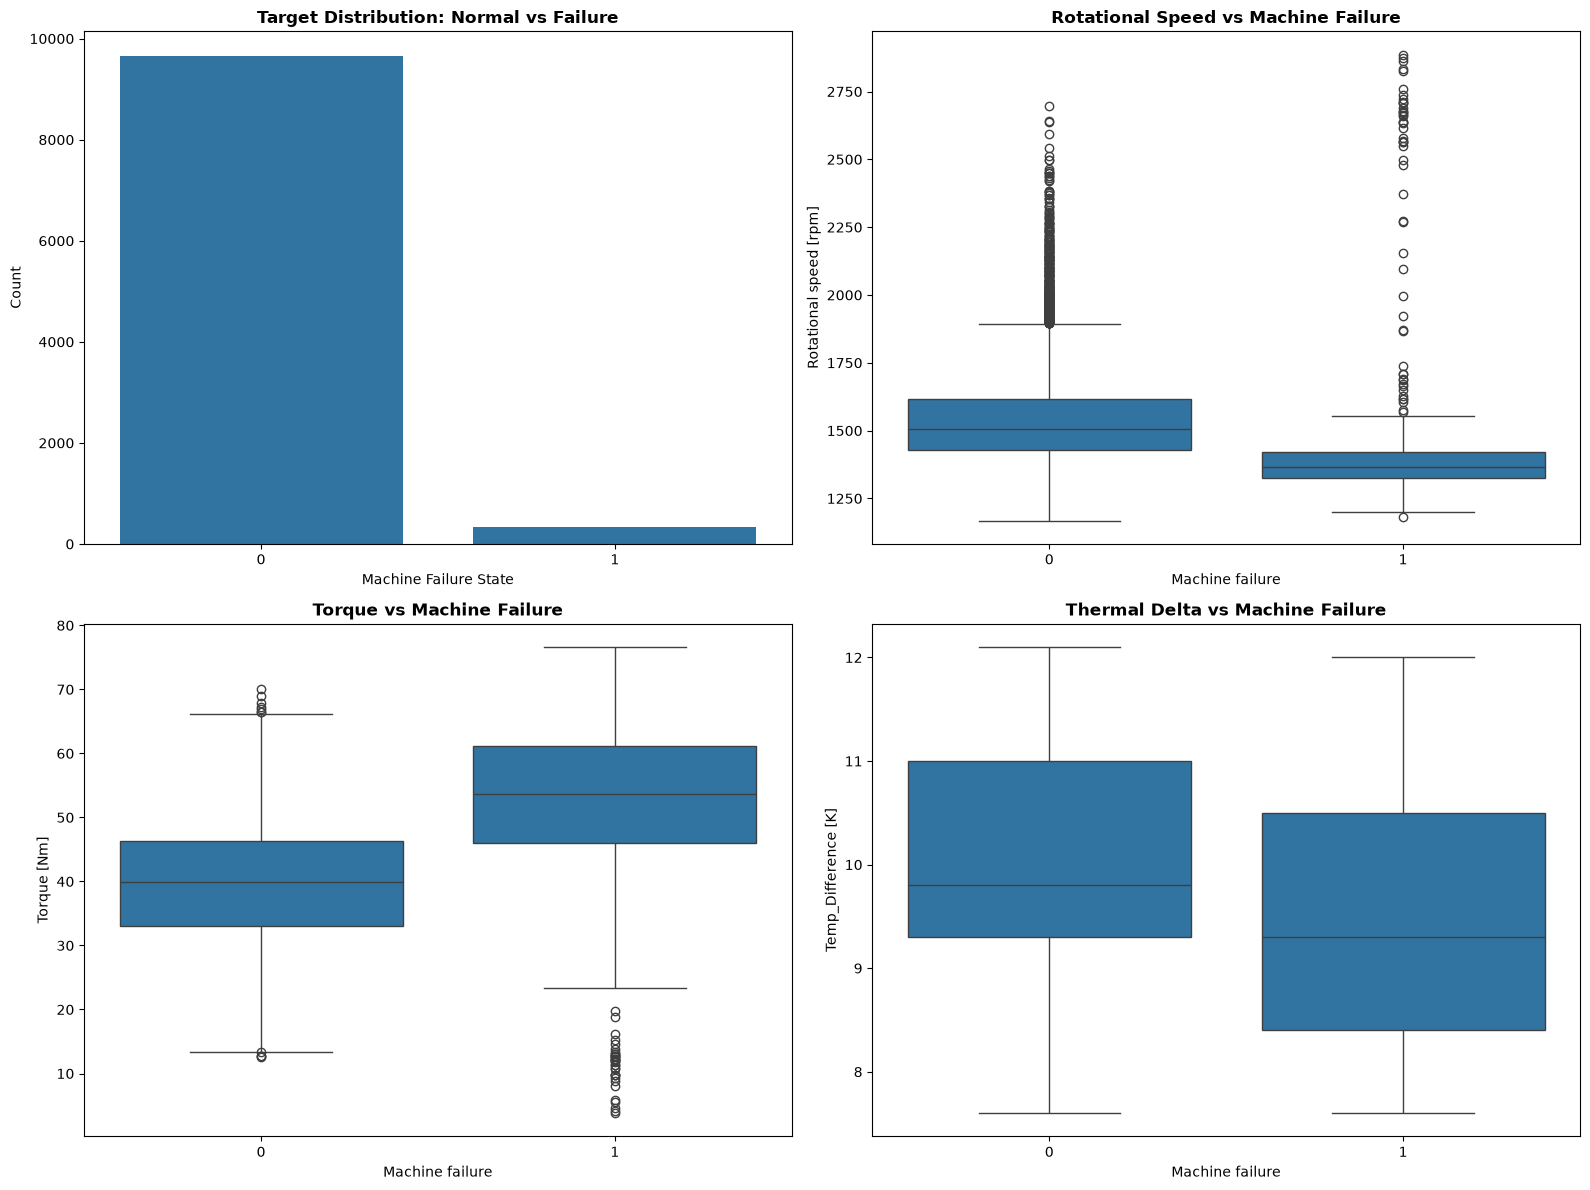

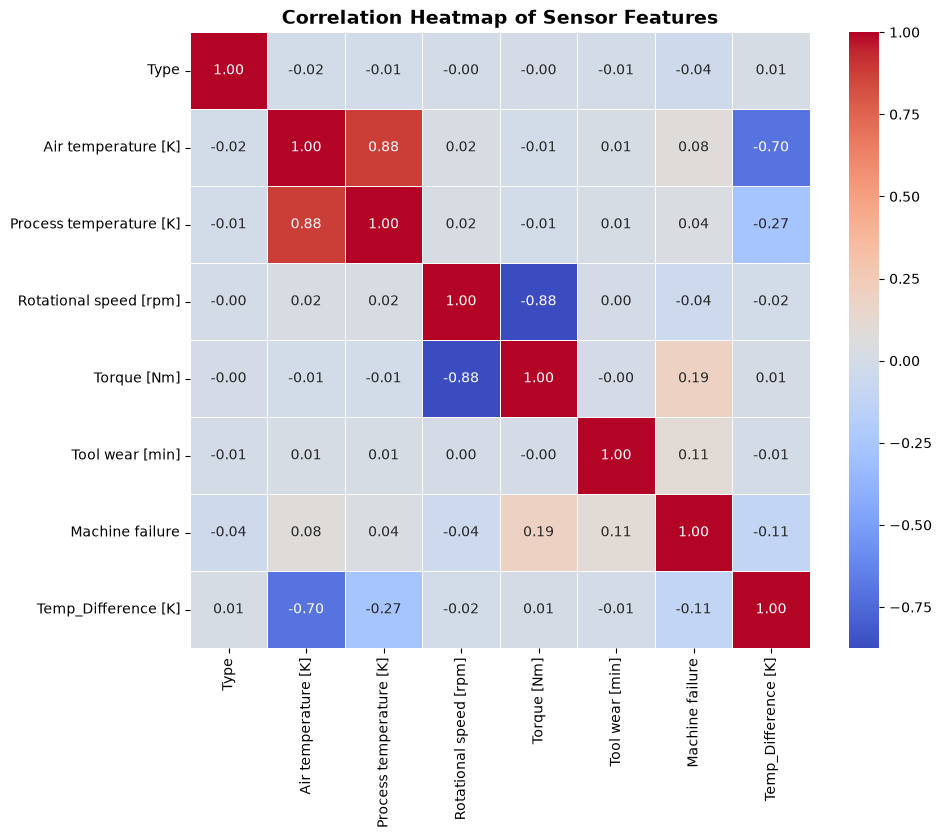

In [57]:
#EDA

# Set up figure styling
plt.figure(figsize=(16, 12))
plt.subplot(2, 2, 1)
sns.countplot(data=df_clean, x='Machine failure')
plt.title('Target Distribution: Normal vs Failure', fontsize=12, fontweight='bold')
plt.xlabel('Machine Failure State')
plt.ylabel('Count')

# Rotational Speed vs Machine Failure
plt.subplot(2, 2, 2)
sns.boxplot(data=df_clean, x='Machine failure', y='Rotational speed [rpm]')
plt.title('Rotational Speed vs Machine Failure', fontsize=12, fontweight='bold')

# Torque vs Machine Failure
plt.subplot(2, 2, 3)
sns.boxplot(data=df_clean, x='Machine failure', y='Torque [Nm]')
plt.title('Torque vs Machine Failure', fontsize=12, fontweight='bold')

# Temperature Delta vs Machine Failure
plt.subplot(2, 2, 4)
sns.boxplot(data=df_clean, x='Machine failure', y='Temp_Difference [K]')
plt.title('Thermal Delta vs Machine Failure', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 8))
correlation_matrix = df_clean.corr()

sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linewidths=0.5
)
plt.title('Correlation Heatmap of Sensor Features', fontsize=14, fontweight='bold')
plt.show()

In [58]:
#Training Data
# Define features and target variable 
X = df_clean.drop(columns=['Machine failure'])
y = df_clean['Machine failure']

# Perform an 80% Train / 20% Test Split 
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20,  
    random_state=50,    
    stratify=y           
)
# why use stratify
# Makes sure that both your Training set and Testing set have the exact same proportion of machine failures as our original dataset

# Print dataset dimensions to verify the split
print(f"Total Dataset Size:   {len(df_clean)} samples")
print(f"Training Set Size:   {len(X_train)} samples (80%)")
print(f"Testing Set Size:    {len(X_test)} samples (20%)")

# Verify class balance across training and testing sets
#this step is imp bcoz
#Counts the Instances, Calculates the Ratio, Exposes False Accuracy
print("\nClass distribution in Training Set (% failures):")
print((y_train.value_counts(normalize=True) * 100).round(2).to_dict())

print("\nClass distribution in Testing Set (% failures):")
print((y_test.value_counts(normalize=True) * 100).round(2).to_dict())

Total Dataset Size:   10000 samples
Training Set Size:   8000 samples (80%)
Testing Set Size:    2000 samples (20%)

Class distribution in Training Set (% failures):
{0: 96.61, 1: 3.39}

Class distribution in Testing Set (% failures):
{0: 96.6, 1: 3.4}


In [59]:
#AI Technique
# We are using random forest classifier bcoz its the best for our kind of data
# Initialize the Random Forest Classifier
# class_weight='balanced' automatically adjusts weights inversely proportional to class frequencies
rf_model = RandomForestClassifier(
    n_estimators=100,      
    max_depth=10,          
    class_weight='balanced', 
    random_state=50        
)
# why did we use class_weight='balanced'
# tells the machine learning model to pay significantly more attention to the rare minority class (Machine Failures) during training.

# Train the model on the scaled training features and labels
rf_model.fit(X_train_scaled, y_train)

# Generate predictions on the unseen testing set
y_pred = rf_model.predict(X_test_scaled)

print("Model Training Completed Successfully!\n")
print(f"Test Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")

# Display Classification Report (Precision, Recall, F1-Score)
print(" Detailed Classification Report ")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Failure (1)']))

Model Training Completed Successfully!

Test Accuracy Score: 97.55%

 Detailed Classification Report 
              precision    recall  f1-score   support

  Normal (0)       0.99      0.98      0.99      1932
 Failure (1)       0.61      0.78      0.68        68

    accuracy                           0.98      2000
   macro avg       0.80      0.88      0.84      2000
weighted avg       0.98      0.98      0.98      2000



Accuracy:  97.55%
Precision: 60.92%
Recall:    77.94%
F1-Score:  68.39%


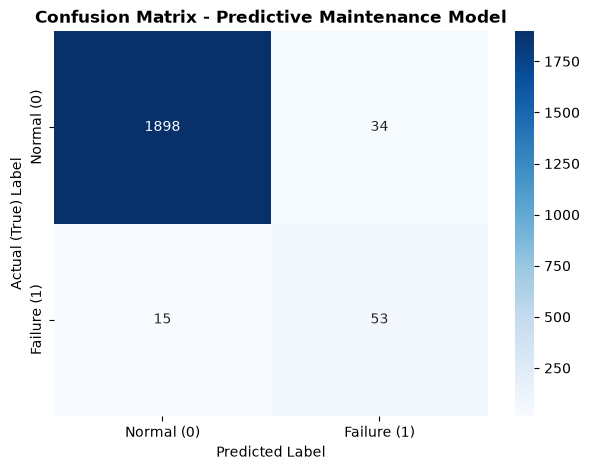

True Negatives (TN - Correctly Normal):  1898
False Positives (FP - False Alarms):    34
False Negatives (FN - Missed Failures): 15
True Positives  (TP - Detected Failures): 53


In [60]:
# Model Evaluation
# Compute Individual Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)


print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")


#  Compute and Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Normal (0)', 'Failure (1)'],
    yticklabels=['Normal (0)', 'Failure (1)']
)
plt.title('Confusion Matrix - Predictive Maintenance Model', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual (True) Label')
plt.show()

# Extract matrix components
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives (TN - Correctly Normal):  {tn}")
print(f"False Positives (FP - False Alarms):    {fp}")
print(f"False Negatives (FN - Missed Failures): {fn}")
print(f"True Positives  (TP - Detected Failures): {tp}")

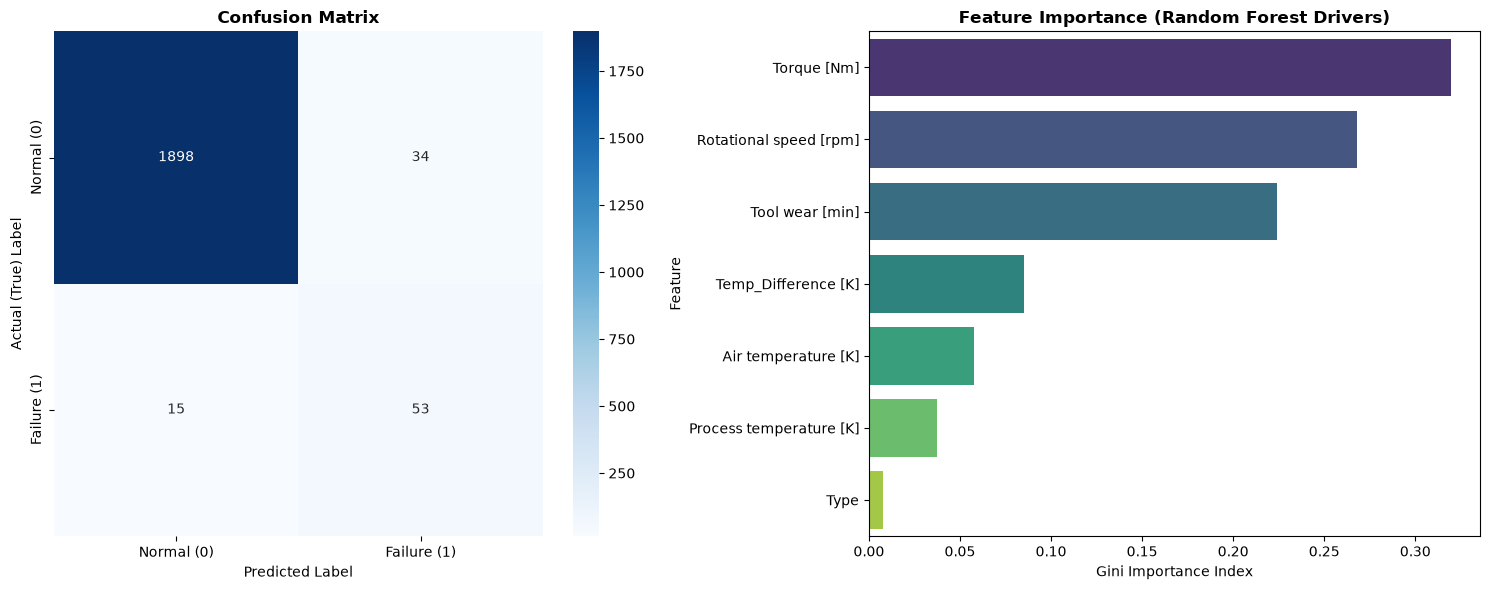

Actual vs Predicted Values
    Actual_State  Predicted_State
0              0                0
1              1                1
2              0                0
3              0                0
4              0                0
5              0                0
6              0                0
7              0                0
8              0                0
9              0                0
10             0                0
11             1                1
12             0                0
13             0                0
14             0                0


In [61]:
# Result and discussion
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal (0)', 'Failure (1)'],
            yticklabels=['Normal (0)', 'Failure (1)'])
axes[0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual (True) Label')

# Feature Importances Extraction
importances = rf_model.feature_importances_
feature_names = X.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values(by='Importance', ascending=False)

sns.barplot(data=feature_imp_df, x='Importance', y='Feature', palette='viridis', ax=axes[1])
axes[1].set_title('Feature Importance (Random Forest Drivers)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gini Importance Index')

plt.tight_layout()
plt.show()

# Actual vs Predicted Values Sample Inspection
results_comparison = pd.DataFrame({
    'Actual_State': y_test.values,
    'Predicted_State': y_pred
})
print("Actual vs Predicted Values")
print(results_comparison.head(15))

In [62]:
# Discussion
# Accuracy~97%  Overall percentage of correct operational state classifications across the test set
# Precision~63% Reliability of breakdown alarms
# Recall (Sensitivity) ~77% Successfully detects over 77% of all actual machine failures before occurrence
# Precision is low as the data is highly biased on one side (Class Imbalance)

In [63]:
# Conclusion 
# 1 What problem was solved?
#   predicting sensor failure based on the conditions it works in
# 2 Which dataset was used?
#   a dataset from kaggle
# 3 Which AI technique was applied?
#   Random Forest Classifier
# 4 What was the performance?
#   Not good enough
# 5 What did you learn from the project?
#   Implementation of AI model

In [ ]:
# Reference
# https://www.youtube.com/watch?v=ifZ9IIQsYW0